<a href="https://colab.research.google.com/github/sebassanchez5680-tech/Prueba/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("college.csv")
df = df[["salary", "cost", "location"]].copy()#copia con las columnas de interes

df["location"] = df["location"].astype("category") #hacemos location a variable categorica
print(df.dtypes)

print(df[["salary", "cost"]].describe()) #estadisticas

print("Registros por localidad:")
print(df["location"].value_counts())

#convirtir location en variables numericas con One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=["location"], drop_first=True, dtype=int) #

print(" filas del DataFrame codificado (One-Hot Encoding):")
print(df_encoded.head())

salary         int64
cost           int64
location    category
dtype: object
              salary           cost
count      85.000000      85.000000
mean    95898.823529  142434.470588
std     11937.121912   53913.064578
min     74900.000000   18260.000000
25%     87100.000000   84670.000000
50%     93200.000000  169200.000000
75%    105000.000000  188700.000000
max    123000.000000  227300.000000
Registros por localidad:
location
NE    25
W     21
S     20
MW    19
Name: count, dtype: int64
 filas del DataFrame codificado (One-Hot Encoding):
   salary    cost  location_NE  location_S  location_W
0  119000  189300            1           0           0
1  121000  189600            1           0           0
2  123000  188400            1           0           0
3  123000  188700            1           0           0
4  110000  194200            1           0           0


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




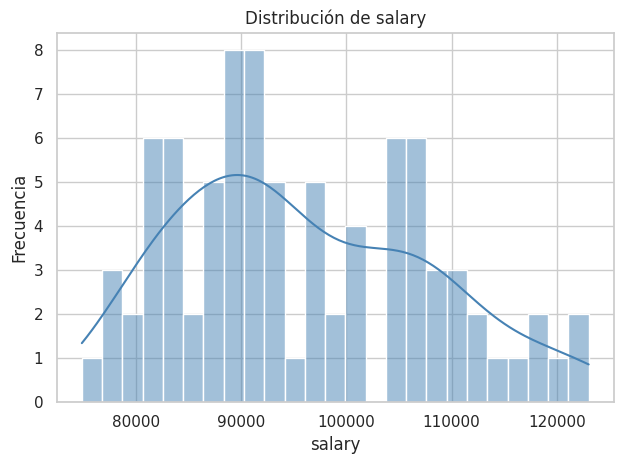

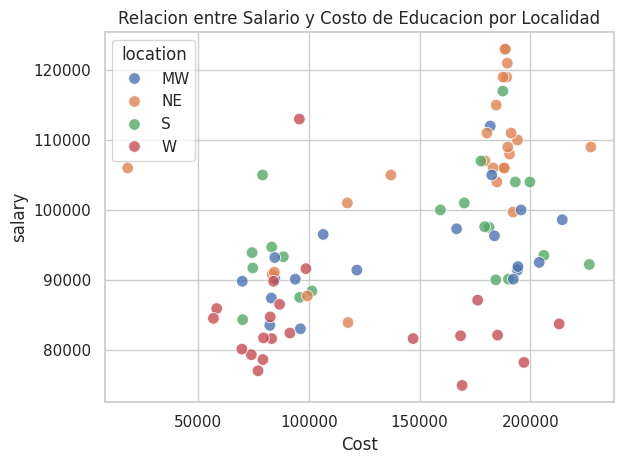

/tmp/ipykernel_1672/3778170543.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="location", y="cost", palette="coolwarm")


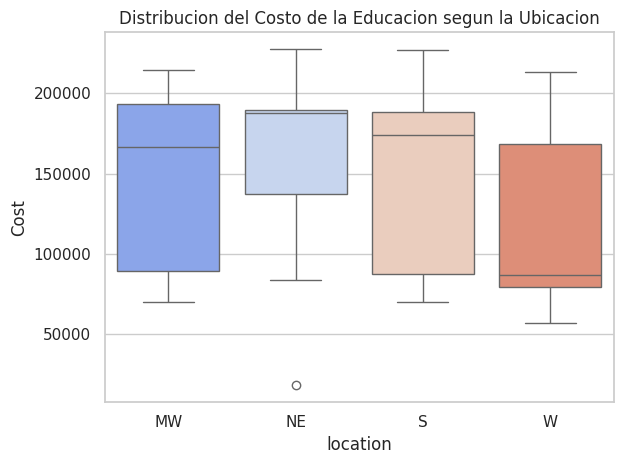

In [41]:
# 1. Histograma
sns.histplot(df["salary"], bins=25, kde=True, color="steelblue")
plt.title("Distribución de salary")
plt.xlabel("salary")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()
# 2. Diagrama de dispersión de salary vs cost (4 colores para location)
sns.scatterplot(data=df,x="cost",y="salary",hue="location",palette="deep",alpha=0.8,s=70)
plt.title("Relacion entre Salario y Costo de Educacion por Localidad")
plt.xlabel("Cost")
plt.ylabel("salary")
plt.legend(title="location")
plt.tight_layout()
plt.show()
# 3. Boxplot de la distribución de 'cost' por 'location'
sns.boxplot(data=df, x="location", y="cost", palette="coolwarm")
plt.title("Distribucion del Costo de la Educacion segun la Ubicacion")
plt.xlabel("location")
plt.ylabel("Cost")
plt.tight_layout()
plt.show()

En el histograma de salary se observa que en 9000 se concentra la mayor cantidad de salarios ademas de que la distribucion parece ser normal sin embargo presenta una cola hacia la derecha.

En el diagrama de dispersion (salary vs cost) apesar de que los datos estan algo dispersos mas si embargo se puede ver una tendencia lineal positiva general (a mayor costo educativo, mayor salario esperado).    

En el boxplot se observa que NE presenta la mediana mas alta, seguida de S y MW, mientras que W tiene la mediana más baja. Asimismo, MW, S y W presentan una dispersion considerable en sus costos indicando una gran variacion en los datos.

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [42]:
from sklearn.linear_model import LinearRegression

X = df_encoded.drop(columns=["salary"])
y = df_encoded["salary"]

modelo = LinearRegression()
modelo.fit(X, y)

print(f"(Beta_0): {modelo.intercept_:.4f}\n")
coeficientes = pd.Series(modelo.coef_, index=X.columns)
print("Coeficientes del modelo:")
print(coeficientes)

(Beta_0): 84988.7162

Coeficientes del modelo:
cost               0.060518
location_NE    12032.819692
location_S      2800.345026
location_W     -7721.420103
dtype: float64


# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

/tmp/ipykernel_1672/558199351.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend()


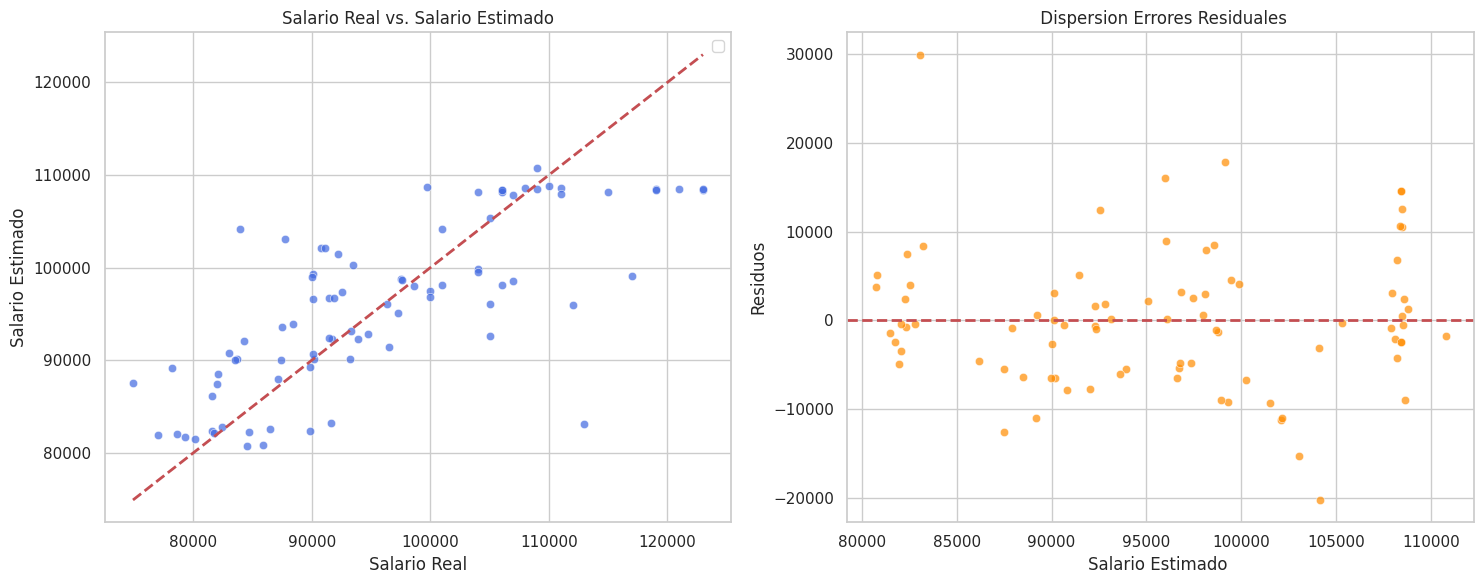

In [43]:
y_pred = modelo.predict(X)
residuos = y - y_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1 salario estimado vs salario real
sns.scatterplot(x=y, y=y_pred, alpha=0.7, ax=axes[0], color="royalblue")
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "--r", linewidth=2)
axes[0].set_xlabel("Salario Real")
axes[0].set_ylabel("Salario Estimado")
axes[0].set_title("Salario Real vs. Salario Estimado")
axes[0].legend()

# 2 Errores residuales vs Predicciones
sns.scatterplot(x=y_pred, y=residuos, alpha=0.7, ax=axes[1], color="darkorange")
axes[1].axhline(y=0, color="r", linestyle="--", linewidth=2)
axes[1].set_xlabel("Salario Estimado ")
axes[1].set_ylabel("Residuos")
axes[1].set_title(" Dispersion Errores Residuales")

plt.tight_layout()
plt.show()

En la grafica salario estimado vs salario real se observa que varios puntos se encuentran alejados de la linea de referencia, dejando ver las diferencias entre los valores reales y las predicciones. Podemos decir que el modelo tiende a sobreestimar algunos salarios bajos y a subestimar algunos salarios altos, lo que sugiere una capacidad de ajuste limitada en ciertos rangos.

En la grafica de dispersion se observa una variabilidad considerable en los errores, asi como algunas observaciones atipicas. Esto sugiere que el modelo presenta dificultades para estimar correctamente determinados salarios y que sus errores no son uniformes.

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [44]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y, y_pred)

print("Desempeño del modelo de regresion:")
print(f"MSE (Error Cuadrático Medio): {mse:.2f}")
print(f"RMSE (Raíz del MSE):          {rmse:.2f}")
print(f"R² Score:                     {r2:.4f} ({r2*100:.2f}%)")

Desempeño del modelo de regresion:
MSE (Error Cuadrático Medio): 60480269.15
RMSE (Raíz del MSE):          7776.91
R² Score:                     0.5705 (57.05%)


RMSE (7,776.91): Indica que, en promedio, las estimaciones de salario del modelo se desvian por aproximadamente $7,777 unidades monetarias del salario real.

R² Score (57.05%): Señala que el 57.05% de la variabilidad o diferencias en los salarios es explicada por el costo de la educación y la ubicación. Esto implica un poder predictivo intermedio; el 42.95% restante del salario depende de variables no incluidas

MSE (60,480,269.15): Al estar en unidades cuadradas, su magnitud es muy grande y dificil de interpretar.   

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [45]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.regression.mixed_linear_model import VCSpec

modelo_ols = smf.ols("salary ~ cost + C(location)", data=df).fit()
print(modelo_ols.summary())

print("\n=== ANOVA Tipo II ===")
tabla_anova = anova_lm(modelo_ols, typ=2)
print(tabla_anova)

vc = {"location": "0 + C(location)"}
modelo_vc = sm.MixedLM.from_formula("salary ~ cost",groups=np.ones(df.shape[0]),vc_formula=vc,data=df).fit()
print("\n=== (MixedLM) ===")
print(modelo_vc.summary())

                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.549
Method:                 Least Squares   F-statistic:                     26.57
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           4.96e-14
Time:                        05:42:34   Log-Likelihood:                -882.12
No. Observations:                  85   AIC:                             1774.
Df Residuals:                      80   BIC:                             1786.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          8.499e+04   3092.65

El modelo es estadisticamente significativo, ya que cuenta con un valor de la prueba F (Prob F-statistic) de $4.96 \times 10^{-14}$, lo que indica que el costo y la localidad en conjunto realmente explican las variaciones en el salario. El $R^2$ confirma que explican el 57.1% de dicha variabilidad. Sin embargo, la advertencia [2] señala un número de condición muy grande ($7.38 \times 10^5$), lo que sugiere una posible multicolinealidad.

El Costo de educacion (cost) es estadisticamente significativo ($p = 0.001$). Su coeficiente de $0.0605$ significa que, manteniendo constante la region, por cada dolar adicional que cuesta la educacion, el salario promedio de los egresados aumenta apenas alrededor de 6 centavos.   
En cuanto a Localidad (location), es altamente significativa ($p = 0.000$) y tiene el mayor impacto positivo, sumando $12,030 al salario promedio respecto a la region de referencia.   

La region W (Oeste) es significativa ($p = 0.004$) pero con un impacto negativo, reduciendo el salario esperado en $7,721 en comparación con la base.   

Mientras que la región S (Sur): Con un p-valor de $0.279$ (mayor a 0.05), la diferencia salarial de $2,800 respecto a la region de referencia no es estadisticamente significativa  

La variable C(location) tiene un valor $PR(>F)$ de $3.57 \times 10^{-10}$, lo que demuestra que la ubicacion geografica es un factor determinante para el salario.   
